**Presentation Code**  
Authors: Eadan (Daisy) Gibb, Elliot Barr

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib import rc
R = 1.0
N = 100

Velocity Verlet  
https://www.algorithm-archive.org/contents/verlet_integration/verlet_integration.html

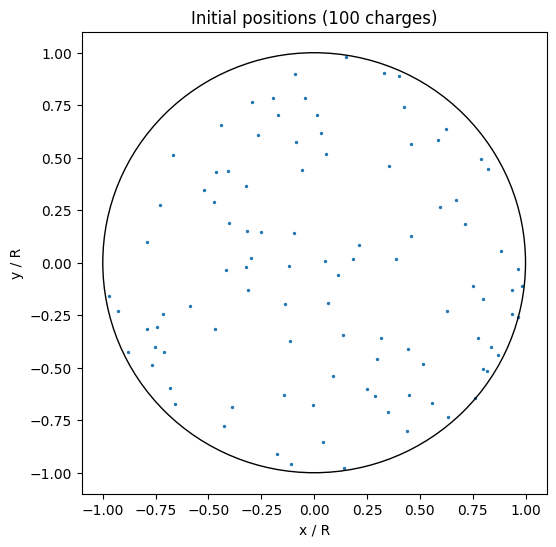

In [ ]:
dt = 1e-3
time = 3
# How many frames we should save
saveTime = 20
# We need a "friction" force to help slow them down so
# This will act like the collisions and such within the metals atoms
friction = 3

# For this we are using unit values like Q is just unit charge, so k,Q,R,etc = 1

rng = np.random.default_rng(0)
randomRadius = R*np.sqrt(rng.random(N)) #Picks a uniformally distributed radius
randomAngle = 2*np.pi*rng.random(N) #Picks a random angle
position = np.zeros((N,2))
x = randomRadius*np.cos(randomAngle)
y = randomRadius*np.sin(randomAngle)
position[:, 0] = x
position[:, 1] = y
p0 = position.copy()
velocity = np.zeros((N,2)) # We can say all start at rest

# Coulombs Forces on all charges
# kq^2 * (ri-rj)/|ri-rj|^3
def forces(P):
    #Need to calculate how far in x and y one particle is from another
    pSize = len(P)
    dx = np.zeros((pSize,pSize))
    dy = np.zeros((pSize,pSize))
    for i in range(pSize):
        for j in range(pSize):
            dx[i,j] = P[i,0] - P[j,0]
            dy[i,j] = P[i,1] - P[j,1]
    # Need to get total distance from i and j
    distance = np.sqrt(dx**2 + dy**2)
    # Diagonals will be it calculating itself so need to set distance to inf
    np.fill_diagonal(distance, np.inf)
    # Force Components
    Fx = np.sum(dx/ distance**3, axis=1)
    Fy = np.sum(dy/ distance**3, axis=1)
    return np.column_stack([Fx,Fy])

def potentialEnergy(P):
    #Need to calculate how far in x and y one particle is from another
    pSize = len(P)
    dx = np.zeros((pSize,pSize))
    dy = np.zeros((pSize,pSize))
    for i in range(pSize):
        for j in range(pSize):
            dx[i,j] = P[i,0] - P[j,0]
            dy[i,j] = P[i,1] - P[j,1]
    # Need to get total distance from i and j
    distance = np.sqrt(dx**2 + dy**2)
    # Diagonals will be it calculating itself so need to set distance to inf
    np.fill_diagonal(distance, np.inf)
    # Potential Energy
    U = np.sum(1/distance)/2
    return U

# Need to account for bouncing and getting caught on the edge
def edge(P, V):
    r = np.sqrt(P[:,0]**2+P[:,1]**2)
    for i in range(len(P)):
        if r[i] > R:
            # calculate the normal/unit vector pointing outward
            nx = P[i,0]/r[i]
            ny = P[i,1]/r[i]
            # With the direction of normal can now place them back on the edge
            P[i,0], P[i,1] = R*nx, R*ny
            # Calculate the velocity they were moving out with
            vOut = V[i,0]*nx + V[i,1]*ny
            # if trying to move outwards bounce back in
            if vOut > 0:
                V[i,0] -= vOut*nx
                V[i,1] -= vOut*ny
    return P,V

# Velocity Verlet Integration
nSteps = int(time/dt)
frames, frameTimes = [], []
# Sets up inital forces
F = forces(position)

for n in range(nSteps+1):
    # We use % because / may lose decimal points all we care to check is if remainder is 0
    if n % saveTime == 0:
        frames.append(position.copy())
        frameTimes.append(n*dt)
    # Using verlet we take a half kick as the start force
    velocity += 0.5*dt*(F-friction*velocity)
    position += dt*velocity
    position, velocity = edge(position, velocity)
    F = forces(position)
    # second half kick as the ending force
    velocity += 0.5*dt*(F-friction*velocity)

# Inital start position chart
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(p0[:, 0], p0[:, 1], s=2)
ax.add_patch(plt.Circle((0, 0), R, fill=False, color='k'))
ax.set_xlabel('x / R')
ax.set_ylabel('y / R')
ax.set_title(f'Initial positions ({N} charges)')
plt.show()

# Animation
fig, ax = plt.subplots(figsize=(6, 6))
dots = ax.scatter(frames[0][:, 0], frames[0][:, 1], s=2)
ax.add_patch(plt.Circle((0, 0), R, fill=False, color='k'))
ax.set_aspect('equal')
ax.set_xlim(-1.1*R, 1.1*R); ax.set_ylim(-1.1*R, 1.1*R)
ax.set_xlabel('x / R'); ax.set_ylabel('y / R')
title = ax.set_title('')

def update(k):
    dots.set_offsets(frames[k])                        # move the dots to frame k
    title.set_text(f'Charges on a conducting disk, t = {frameTimes[k]:.2f}')
    return dots, title

ani = FuncAnimation(fig, update, frames=len(frames), interval=40)
plt.close(fig)

ani.save('charges.gif', writer='pillow', fps=25)
rc("animation", html="jshtml")
ani